In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os

print("TensorFlow Version:", tf.__version__)
print("Project setup successful!")

TensorFlow Version: 2.21.0
Project setup successful!


In [3]:
!pip install -q importlib-resources

In [1]:
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)
print("TFDS imported successfully!")

TensorFlow: 2.21.0
TFDS imported successfully!


In [2]:
dataset, info = tfds.load(
    "plant_village",
    split="train",
    as_supervised=True,
    with_info=True
)

print("Total images:", info.splits["train"].num_examples)
print("Total categories:", info.features["label"].num_classes)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.PWQ3JK_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Total images: 54303
Total categories: 38


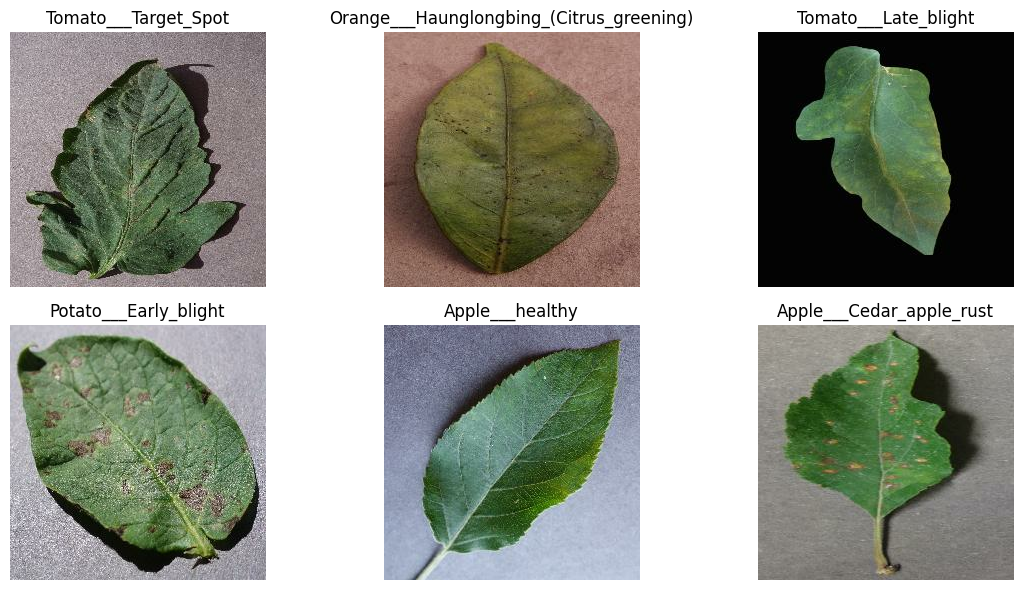

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for i, (image, label) in enumerate(dataset.take(6)):
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(info.features["label"].int2str(label.numpy()))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [5]:
# Split the dataset
total = info.splits["train"].num_examples
train_size = int(total * 0.8)

train_raw = dataset.take(train_size)
val_raw = dataset.skip(train_size)

print("Total images:", total)
print("Training images:", train_size)
print("Validation images:", total - train_size)

Total images: 54303
Training images: 43442
Validation images: 10861


In [6]:
IMG_SIZE = 128
BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_ds = (
    train_raw
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_ds = (
    val_raw
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

print("Training and validation datasets are ready!")

Training and validation datasets are ready!


In [7]:
import tensorflow as tf

NUM_CLASSES = info.features["label"].num_classes

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),

    # Learn leaf patterns and features
    tf.keras.layers.Conv2D(
        32, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        64, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.Conv2D(
        128, (3, 3), activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Classification layers
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │         4,902 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,309,542 (12.62 MB)

 Trainable params: 3,309,542 (12.62 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1635s 1s/step - accuracy: 0.5999 - loss: 1.4107 - val_accuracy: 0.8250 - val_loss: 0.5596
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1573s 1s/step - accuracy: 0.7975 - loss: 0.6533 - val_accuracy: 0.8535 - val_loss: 0.4686
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1499s 1s/step - accuracy: 0.8490 - loss: 0.4686 - val_accuracy: 0.9058 - val_loss: 0.2930
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1510s 1s/step - accuracy: 0.8795 - loss: 0.3624 - val_accuracy: 0.9187 - val_loss: 0.2562
Epoch 5/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 1485s 1s/step - accuracy: 0.9059 - loss: 0.2829 - val_accuracy: 0.9097 - val_loss: 0.2944


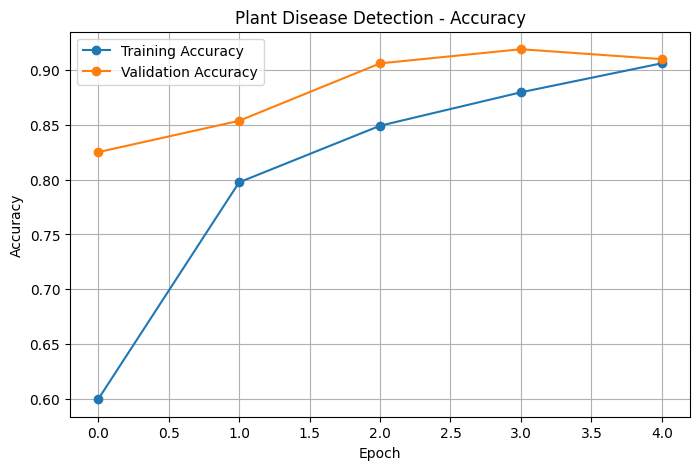

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], marker="o",
         label="Training Accuracy")
plt.plot(history.history["val_accuracy"], marker="o",
         label="Validation Accuracy")

plt.title("Plant Disease Detection - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

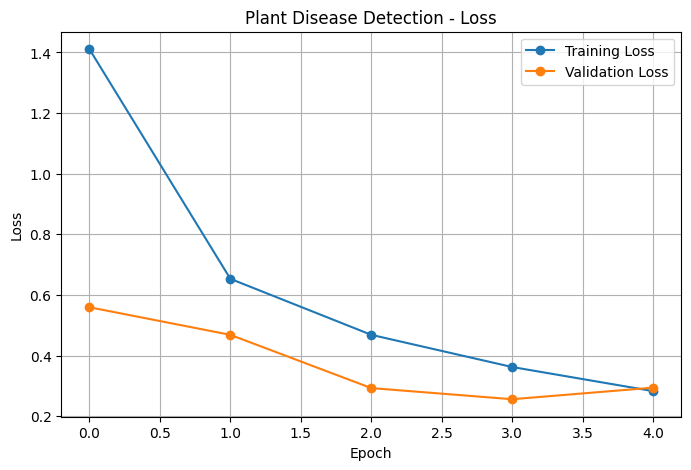

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], marker="o",
         label="Training Loss")
plt.plot(history.history["val_loss"], marker="o",
         label="Validation Loss")

plt.title("Plant Disease Detection - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
model.save("plant_disease_cnn.keras")

print("Model saved successfully!")

Model saved successfully!


Saving leaf.jpeg to leaf.jpeg


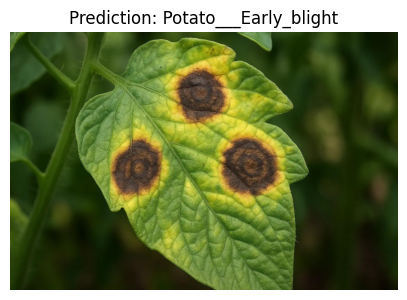

Predicted category: Potato___Early_blight
Model confidence: 58.69%


In [12]:
from google.colab import files
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

uploaded = files.upload()

for filename in uploaded.keys():
    img = Image.open(filename).convert("RGB")
    img = img.resize((128, 128))

    image_array = np.array(img).astype("float32") / 255.0
    image_array = np.expand_dims(image_array, axis=0)

    prediction = model.predict(image_array, verbose=0)
    predicted_index = int(np.argmax(prediction))
    confidence = float(np.max(prediction)) * 100

    class_name = info.features["label"].int2str(predicted_index)

    plt.figure(figsize=(5, 5))
    plt.imshow(Image.open(filename))
    plt.axis("off")
    plt.title(f"Prediction: {class_name}")
    plt.show()

    print("Predicted category:", class_name)
    print(f"Model confidence: {confidence:.2f}%")

In [13]:
# Show top 3 predictions

top3 = np.argsort(prediction[0])[-3:][::-1]

print("Top 3 Predicted Categories:\n")

for index in top3:
    name = info.features["label"].int2str(int(index))
    score = prediction[0][index] * 100

    print(f"{name}: {score:.2f}%")

Top 3 Predicted Categories:

Potato___Early_blight: 58.69%
Corn___Common_rust: 35.92%
Tomato___Late_blight: 3.17%


In [14]:
!pip -q install gradio

In [15]:
import gradio as gr
import numpy as np
import tensorflow as tf

def predict_disease(image):
    if image is None:
        return {"Please upload a leaf image": 1.0}

    # Resize and normalize image
    image = image.convert("RGB").resize((128, 128))
    image = np.array(image).astype("float32") / 255.0
    image = np.expand_dims(image, axis=0)

    # Predict
    probabilities = model.predict(image, verbose=0)[0]

    # Get top 3 categories
    top_indices = np.argsort(probabilities)[-3:][::-1]

    results = {}
    for idx in top_indices:
        label = info.features["label"].int2str(int(idx))
        results[label] = float(probabilities[idx])

    return results


demo = gr.Interface(
    fn=predict_disease,
    inputs=gr.Image(type="pil", label="Upload a Plant Leaf Image"),
    outputs=gr.Label(num_top_classes=3, label="Top Predictions"),
    title="🌿 Plant Disease Detection using CNN",
    description=(
        "Upload a plant leaf image to see the model's top 3 predicted categories. "
        "Predictions are for educational use and are not a confirmed diagnosis."
    )
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://14c07f44553266253d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
